# Actividad | Dataset - Notebook | Individual
**Alumno:** Gemma Alejandra Martínez Santos   
**Matrícula:** A01652255    
**Curso:** TC5061.10 - Maestría en Inteligencia Artificial Aplicada

--------
**Descripción general de la Database de acuerdo a la información proporcionada por kaggle (IBM Telco Customer Churn)**    
Busca predecir si un cliente abandonará la empresa ("Churn"). Por lo tanto la variable target es "Churn" que indica si el cliente se dio de baja en el último mes.    
El dataframe contiene 7,043 filas (clientes) y 21 columnas (características/variables). Esta información se divide en 4 categorias principales.    
* Churn: baja de clientes
* Demográficos: Género, edad y situación actual (pareja/dependientes).
* Servicios contratados: Telefonía, internet, seguridad, respaldo, soporte técnico y streaming.
* Cuenta: Tiempo que lleva siendo cliente, tipo de contrato, método de pago, cargos mensuales y totales.

**Descripción de las variables**

- `customerID`: identificador del cliente.
- `gender`: género registrado del cliente.
- `SeniorCitizen`: indicador de cliente adulto mayor.
- `Partner`: indica si tiene pareja.
- `Dependents`: indica si tiene dependientes.
- `tenure`: meses que el cliente ha permanecido con la compañía.
- `PhoneService`: servicio telefónico.
- `MultipleLines`: servicio de múltiples líneas.
- `InternetService`: tipo de servicio de internet.
- `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`: servicios adicionales.
- `StreamingTV`, `StreamingMovies`: servicios de entretenimiento.
- `Contract`: tipo de contrato.
- `PaperlessBilling`: facturación electrónica.
- `PaymentMethod`: método de pago.
- `MonthlyCharges`: cargos mensuales.
- `TotalCharges`: cargos acumulados.
- `Churn`: variable objetivo; indica si el cliente abandonó el servicio.
-------

**PIPs y librerias**

In [1]:
# Pendientes por instalar
#!pip install kagglehub
#!pip install mlflow


In [2]:
# Librerias a utilizar
# Librerias base con operaciones numericas, visualización y datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import kagglehub

#Librerias para la fase de modelado y métricas
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
                                accuracy_score,
                                precision_score,
                                recall_score,
                                f1_score,
                                roc_auc_score,
                                confusion_matrix,
                                classification_report,
                                ConfusionMatrixDisplay,
                                RocCurveDisplay)

# Librerias de MLflow de experimentos de ML
import mlflow
import mlflow.sklearn

------
**Carga del archivo**

In [3]:
# Descargar la última versión del dataset usando kagglehub
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\gemma\.cache\kagglehub\datasets\blastchar\telco-customer-churn\versions\1


In [4]:
# Cargar el archivo CSV en un DataFrame
df = pd.read_csv(os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv"))
df_copy = df.copy() # Copia de DF original para no modificar nada

------
**Carga y describe el dataset**

In [5]:
# Descripción general del adtaframe
print(f"\nNúmero de registros (filas): {df.shape[0]}")
print(f"Número de variables (columnas): {df.shape[1]}")

display(df.head())


Número de registros (filas): 7043
Número de variables (columnas): 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Análisis exploratorio (EDA)**

In [6]:
# Analisis cin tipo de dato por col, valores nulo y no nulos, los valores únicos, duplicados 
resumen = pd.DataFrame({
    "Tipo_dato": df.dtypes.astype(str),
    "Registros": df.count(),
    "Val_unicos": df.nunique(),
    "Blancos": df.isna().sum(),
    "Duplicados": df.duplicated().sum(),})

display(resumen)

,Tipo_dato,Registros,Val_unicos,Blancos,Duplicados
customerID,object,7043,7043,0,0
gender,object,7043,2,0,0
SeniorCitizen,int64,7043,2,0,0
Partner,object,7043,2,0,0
Dependents,object,7043,2,0,0
tenure,int64,7043,73,0,0
PhoneService,object,7043,2,0,0
MultipleLines,object,7043,3,0,0
InternetService,object,7043,3,0,0
OnlineSecurity,object,7043,3,0,0


In [7]:
duplicados = df_copy.duplicated().sum()

print(f"Filas duplicadas encontradas: {duplicados}")

if duplicados > 0:
    df_copy = df_copy.drop_duplicates()
    print(f"Filas después de eliminar duplicados: {len(df_copy)}")
else:
    print("No se encontraron filas duplicadas; no fue necesario eliminarlas.")

Filas duplicadas encontradas: 0
No se encontraron filas duplicadas; no fue necesario eliminarlas.


--------
**Limpieza**    
Espacios en blanco

In [8]:
# Detección de nulos y de espacios
print(df_copy.isnull().sum())
print((df_copy == " ").sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [9]:
# Desgloce de datos que tienen espacio
blancos = df_copy[df_copy['TotalCharges'] == " "]
print(f"Cantidad de espacios en blanco encontrados: {len(blancos)}")
print(blancos[['tenure', 'MonthlyCharges', 'TotalCharges']])

Cantidad de espacios en blanco encontrados: 11
      tenure  MonthlyCharges TotalCharges
488        0           52.55             
753        0           20.25             
936        0           80.85             
1082       0           25.75             
1340       0           56.05             
3331       0           19.85             
3826       0           25.35             
4380       0           20.00             
5218       0           19.70             
6670       0           73.35             
6754       0           61.90             


In [10]:
df_copy['TotalCharges'] = pd.to_numeric(df_copy['TotalCharges'], errors='coerce') # Covierte a float
df_copy['TotalCharges'] = df_copy['TotalCharges'].fillna(0) # Se les asigna 0 para posteriormente poder trabajar con el modelo

---------
Variable objetivo a Yes/No

In [11]:
print("\nVariables de Churn:") # datos actuales en Churn
print(df_copy['Churn'].value_counts())


Variables de Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [12]:
df_copy['Churn'] = df_copy['Churn'].apply(lambda x: 1 if x == 'Yes' else 0) # Pasan a 0 y 1
print("\nVariables de Churn:")
print(df_copy['Churn'].value_counts()) # Datos actuales en Churn


Variables de Churn:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [13]:
# Limpiamos al inicio y al final por si existe algún espcio
text_columns = df_copy.select_dtypes(include=["object"]).columns

for col in text_columns:
    df_copy[col] = df_copy[col].str.strip()

Observamos que la variable TotalCharges no tenía nulos, estaba almacenada como texto era un espacio en blanco (" "). Esto se puede deber a que son clientes recientes por lo que aún no se guardan los pagos en el total.    
Esto se le pone 0, permite conservar los registros y mantiene la información del cliente y los datos acumulados.

De igual forma se reviso la parte de duplicados, evitando que algún cliente pueda aparecer más de una vez, sin embargo nos dió 0 por lo que no fue necesario eliminar ningún registro.

También la variable objetivo se cambió a binario para que en un futuro que se haga el proceso del modelo, se pueda ejecutar correctamente.

Los espacios del inicio y el final por temas de limpieza también se eliminaron.

A continuación podemos ver de que forma quedan los datos y con ello podemos identificar el tipo de variable.

Comprobación de datos actuales

In [14]:
espacios_despues = {}

for col in text_columns:
    espacios_despues[col] = {
        "cadenas_vacias": (df_copy[col] == "").sum(),
        "solo_espacios": df_copy[col].astype(str).str.strip().eq("").sum(),
        "espacios_inicio_fin": (
            df_copy[col].astype(str) != df_copy[col].astype(str).str.strip()).sum()}

espacios_despues_df_copy = pd.DataFrame(espacios_despues).T

display(espacios_despues_df_copy)

,cadenas_vacias,solo_espacios,espacios_inicio_fin
customerID,0,0,0
gender,0,0,0
Partner,0,0,0
Dependents,0,0,0
PhoneService,0,0,0
MultipleLines,0,0,0
InternetService,0,0,0
OnlineSecurity,0,0,0
OnlineBackup,0,0,0
DeviceProtection,0,0,0


In [15]:
tabla_tipos = pd.DataFrame({"tipo_dato": df_copy.dtypes.astype(str), "valores_unicos": df_copy.nunique(), "faltantes": df_copy.isna().sum()})

display(tabla_tipos)

,tipo_dato,valores_unicos,faltantes
customerID,object,7043,0
gender,object,2,0
SeniorCitizen,int64,2,0
Partner,object,2,0
Dependents,object,2,0
tenure,int64,73,0
PhoneService,object,2,0
MultipleLines,object,3,0
InternetService,object,3,0
OnlineSecurity,object,3,0


Clasificamos variable spara saber como vamos a proceder con la parte visual

In [16]:
# Clasificación de variables

var_indicador = ["customerID"]

var_obj = ["Churn"]

var_num = var_num = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

var_cat = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

print("Variable indicador: ", var_indicador)
print("Variable objetivo: ",var_obj)
print("\nVariables numéricas: ", var_num)

print("\nVariables categóricas:")
print(var_cat)

var_tot = var_indicador + var_obj + var_cat + var_num
print("\nVariables totales: ", len(var_tot))
print(var_tot)

Variable indicador:  ['customerID']
Variable objetivo:  ['Churn']

Variables numéricas:  ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Variables categóricas:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Variables totales:  21
['customerID', 'Churn', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


-------
**Visualizaciones**

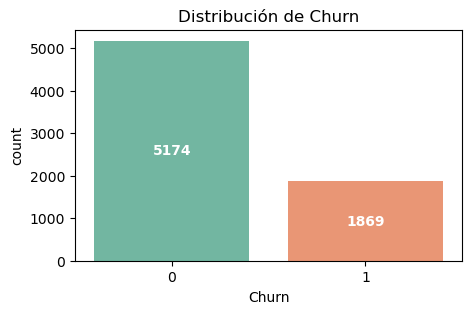

In [17]:
plt.figure(figsize=(5, 3))
ax = sns.countplot(x='Churn', hue='Churn', data=df_copy, palette='Set2', legend=False)
plt.title('Distribución de Churn')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2.),
                ha='center', va='center', color='white', fontweight='bold')
plt.show()

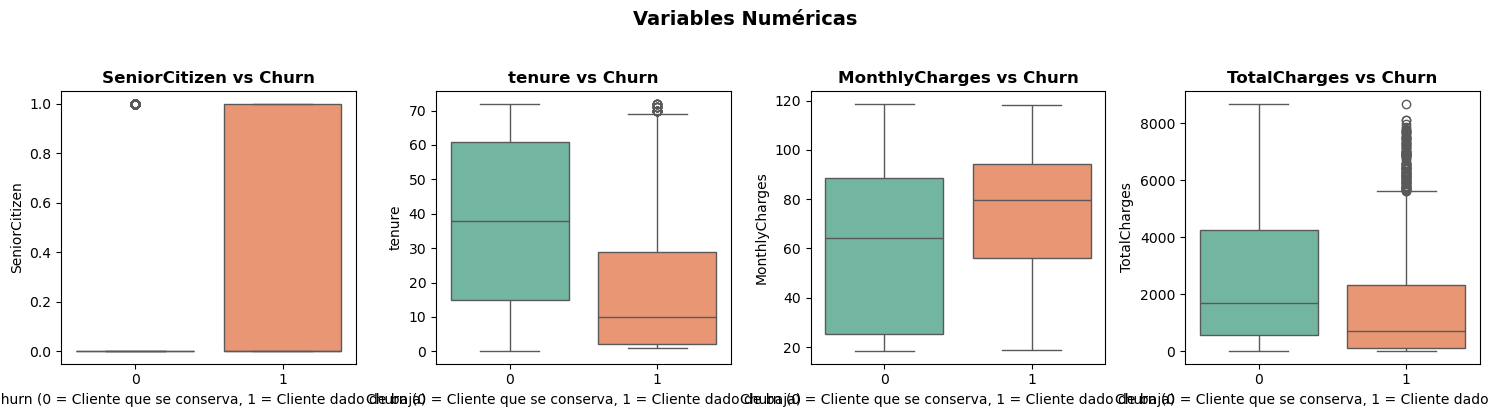

In [18]:
fig, axes = plt.subplots(1, len(var_num), figsize=(15, 4))

for i, col in enumerate(var_num):
    sns.boxplot(data=df_copy, x='Churn', y=col, hue='Churn', ax=axes[i], palette='Set2', legend=False)
    axes[i].set_title(f'{col} vs Churn', fontweight='bold')
    axes[i].set_xlabel('Churn (0 = Cliente que se conserva, 1 = Cliente dado de baja)')
    axes[i].set_ylabel(col)

plt.suptitle('Variables Numéricas', y=1.03, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

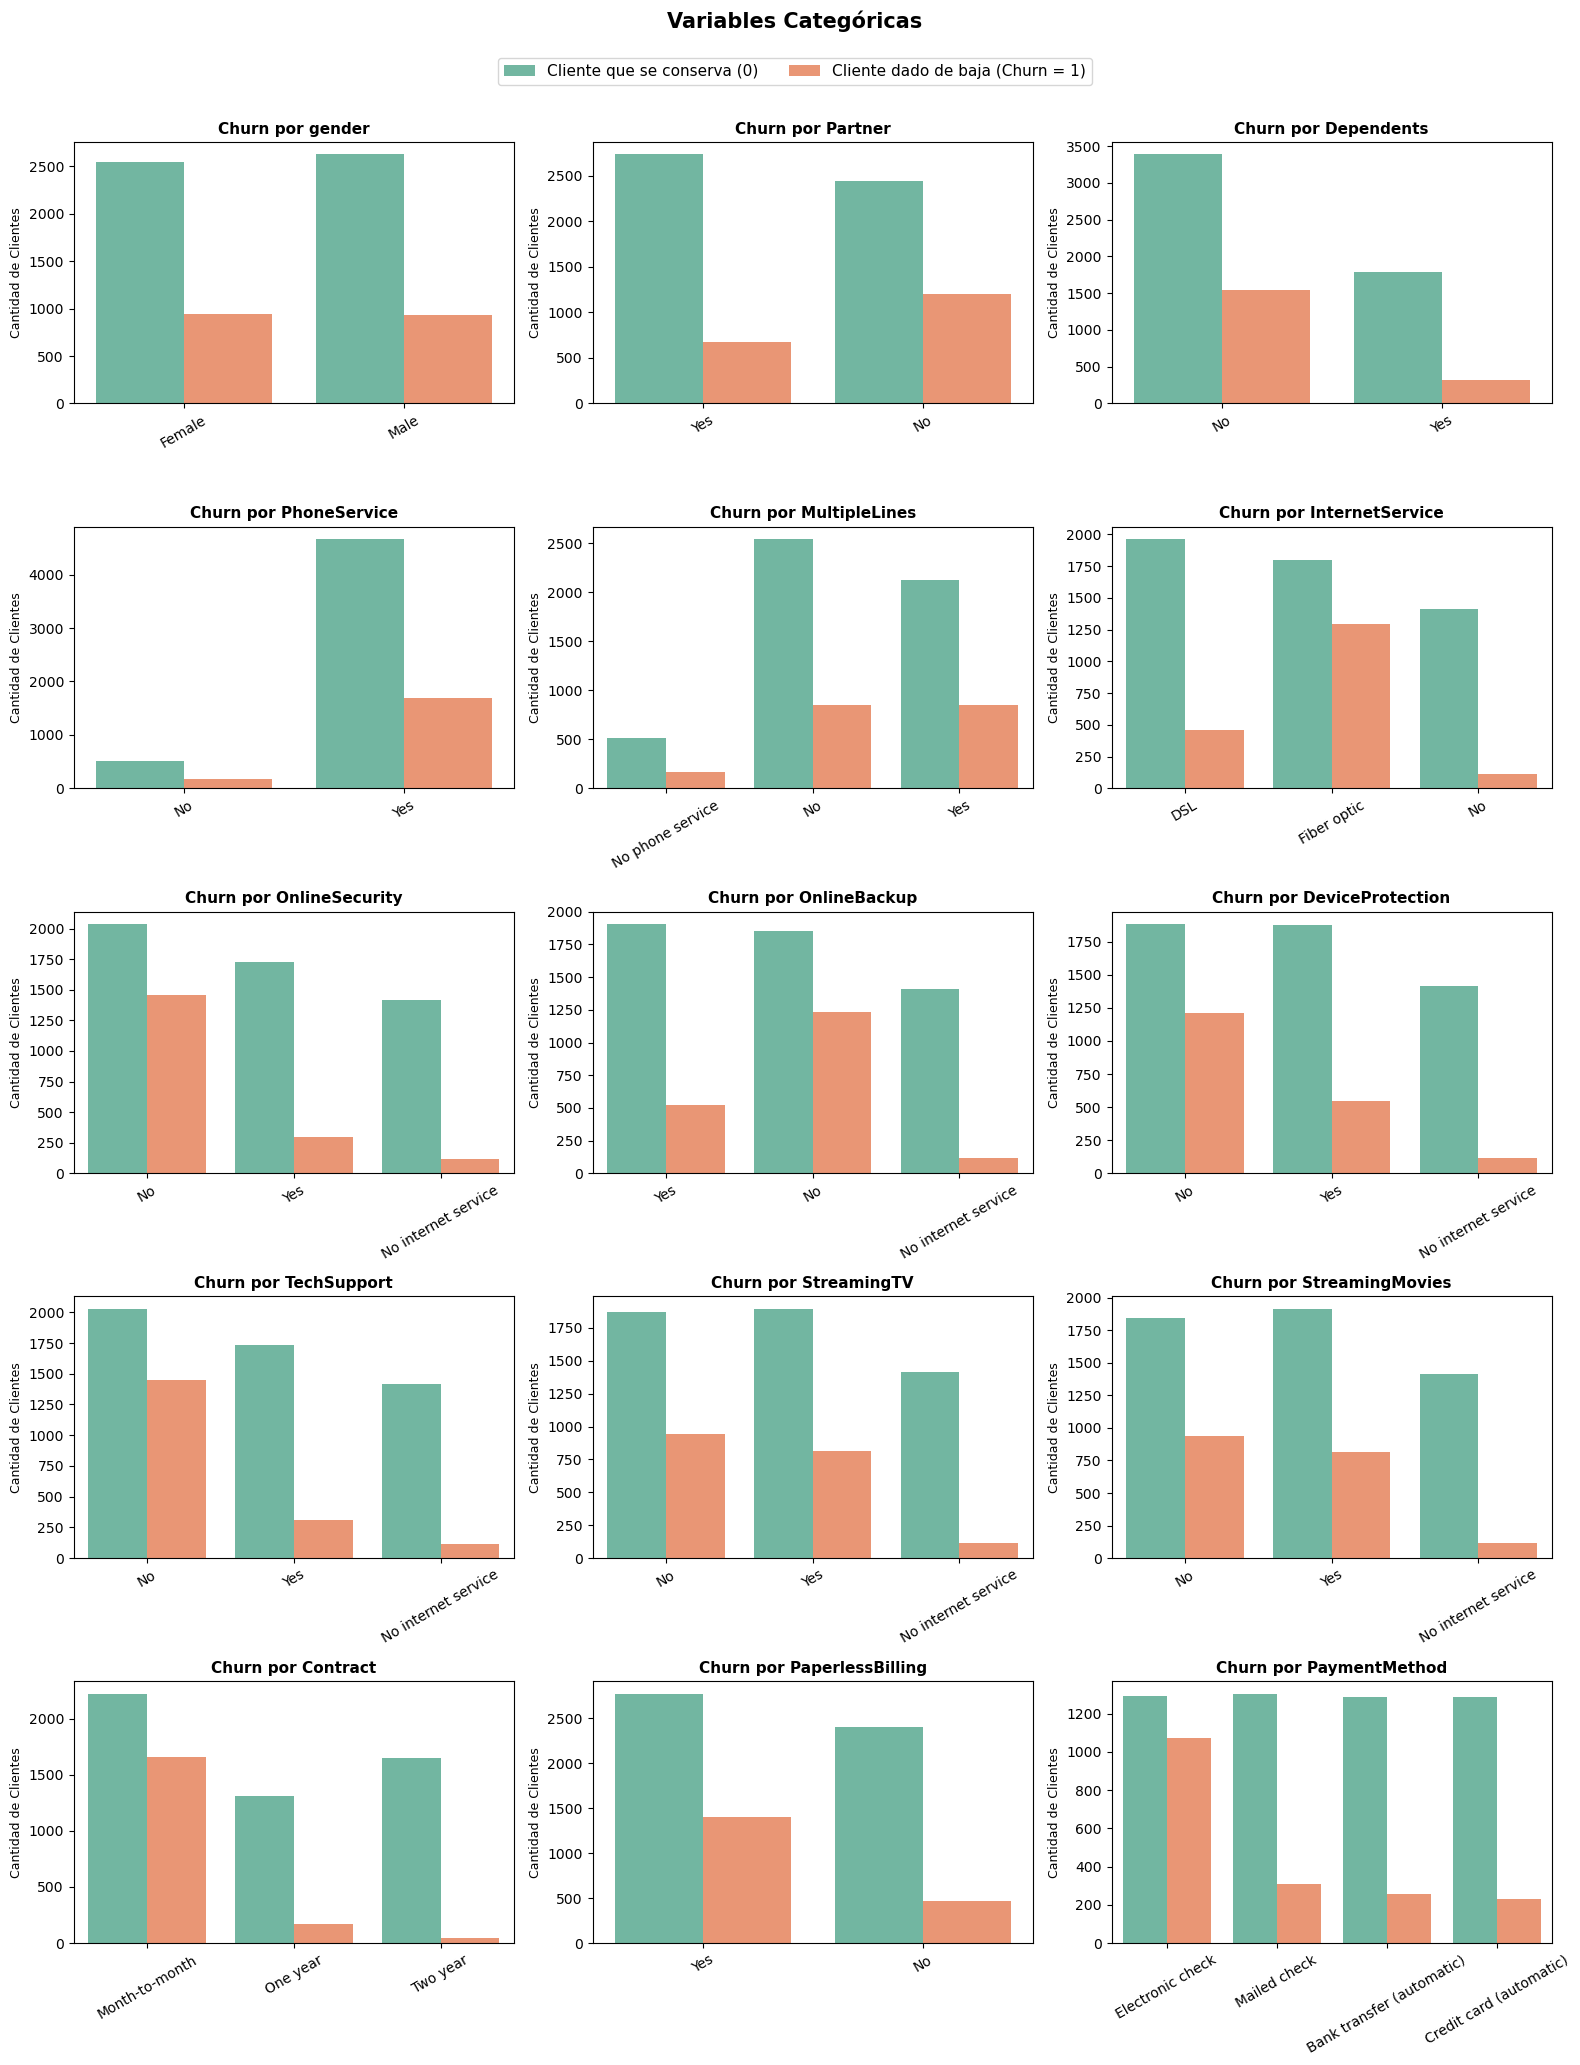

In [19]:
n_cols = 3
n_rows = (len(var_cat) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 4))

if n_rows == 1:
    axes = [axes] if n_cols == 1 else list(axes)
else:
    axes = axes.flatten()

for i, col in enumerate(var_cat):
    sns.countplot(data=df_copy, x=col, hue='Churn', ax=axes[i], palette='Set2')
    axes[i].set_title(f'Churn por {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Cantidad de Clientes', fontsize=9)
    axes[i].tick_params(axis='x', rotation=30)
    
    if axes[i].get_legend():
        axes[i].get_legend().remove()

# Formato cuadricula por si hay espacios vacios
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Variables Categóricas', y=1.03, fontsize=15, fontweight='bold')
handles, labels = axes[0].get_legend_handles_labels()
labels = ['Cliente que se conserva (0)', 'Cliente dado de baja (Churn = 1)']
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.01), ncol=2, fontsize=11, frameon=True)

plt.tight_layout()
plt.show()

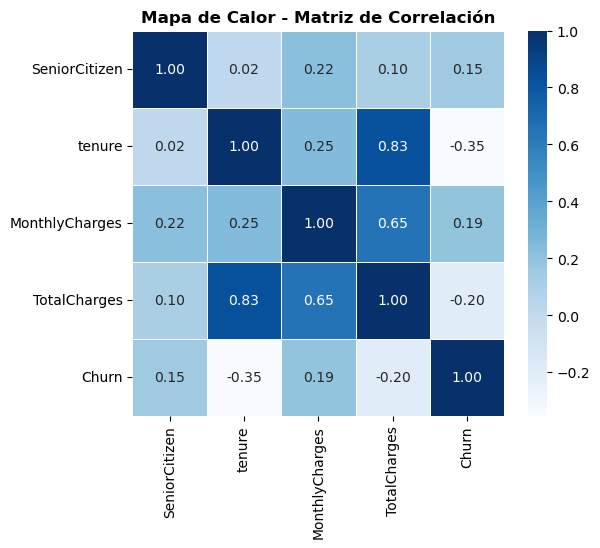

In [20]:
plt.figure(figsize=(6, 5))
df_corr = df_copy.copy()
if df_corr['Churn'].dtype == 'object':
    df_corr['Churn'] = df_corr['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

corr = df_corr[var_num + ['Churn']].corr()

sns.heatmap(corr, annot=True, cmap='Blues', fmt='.2f', linewidths=0.5, cbar=True)
plt.title('Mapa de Calor - Matriz de Correlación', fontweight='bold')
plt.show()

Mediante las visualización podemos ver como se comporta la variable objetivo. Es importante para el modelo, ya que nos podemos dar cuenta del comportamiento de las diferentes variables. La variable `Churn` muestra cuántos clientes permanecieron y cuántos cancelaron el servicio. 

Tanto en los histogramas como en los boxplots  permiten observar la distribución. En el caso de `tenure` presenta concentración en clientes con menor antigüedad; `TotalCharges`tiene valores más altos porque es la suma de todo; `MonthlyCharges` tiene un amplio rango por los diferentes precios. Aunque en los boxplots tengan algunos outliers estos no me causan una preocupación debido a que se puede probocar por la antiguedad del cliente

Las gráficas de barras muestran la frecuencia (cuantas veces se repite) de las diferentes categorías del dataset. Algunas variables presentan categorías claramente predominantes, mientras que otras tienen una distribución más equilibrada. Con esto podemos ver las caracteristicas del cliente.

El mapa de calor muestra la relación entre las variables numéricas. `tenure`, `MonthlyCharges` y `TotalCharges` presentan diferentes niveles de asociación, destacando la relación entre `tenure` y `TotalCharges`, pobablemente es porque mientras va avanzando el tiempo aumenta el total del costo.


Estadisticas

In [21]:
# Estadísticas variables numéricas

print("Estadísticas variables numéricas:")

display(df_copy[var_num].describe().T)

Estadísticas variables numéricas:


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


In [22]:
# Estadísticasvariables categóricas

print("Estadísticas variables categóricas:")

display(df_copy[var_cat].astype("object").describe().T)

Estadísticas variables categóricas:


,count,unique,top,freq
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095
TechSupport,7043,3,No,3473


Ya una vez teniendo estos datos podemos identificar claramente a que categoría pertenece de acuerdo al tipo de dato. La variable Churn se ocupa como objetivo y la parte del ID es para ocuparlo como identificador.

-----------

**Entrena un modelo base**

In [23]:
df_model = df_copy.copy()

y = df_model["Churn"] # Variable objetivo
X = df_model.drop(columns=["Churn", "customerID"]) # Variables predictoras

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (7043, 19)
Dimensiones de y: (7043,)


In [24]:
# Definir variables
v_num_mod = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
v_cat_mod = X.select_dtypes(include=["object"]).columns.tolist()

print("Variables numéricas: ",v_num_mod)
print("\nVariables categóricas: ", v_cat_mod)

Variables numéricas:  ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Variables categóricas:  ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [25]:
preprocessor = ColumnTransformer(transformers=[ # Aplica transformaciones para ambas variables 
        ('num', StandardScaler(), var_num),# Estandariza xarriables
        ('cat', OneHotEncoder(handle_unknown='ignore'), var_cat)]) # Convierte a varioables con resultados binarios

# Automatiza el procesamiento y entrenamiento del modelo
pipeline = Pipeline(steps=[('preprocessor', preprocessor), 
                           ('classifier', LogisticRegression(max_iter=1000, random_state=42))]) # Se ultiliza un modelo de regresión logistica con 100 iteraciones con seed de 42

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y) # Dividimos los datos 80% y 20% de train test, se fija el seed

print("Dimensiones de X_train:", X_train.shape)
print("Dimensiones de X_test:", X_test.shape)
print("Dimensiones de y_train:", y_train.shape)
print("Dimensiones de y_test:", y_test.shape)

Dimensiones de X_train: (5634, 19)
Dimensiones de X_test: (1409, 19)
Dimensiones de y_train: (5634,)
Dimensiones de y_test: (1409,)


In [27]:
# Ejeculta lo visto en el preprocesamienrto y entrena el modelo
pipeline.fit(X_train,y_train) 
print("Modelo OK")

Modelo OK


In [28]:
y_pred = pipeline.predict(X_test) # Predicción de clase (0 / 1)
y_prob = pipeline.predict_proba(X_test)[:, 1] # Probabilidad que el cliente se de de baja

print("Predicciones OK")

Predicciones OK


Como se menciona a lo largo del código, se utiliza standardScaler para la diferencia entre escalas; mientras que OneHotEncoder es para transformar a numérico lo categórico.
Ocupando el código previo se utiliza el pipeline para realizar las transformaciones de una forma secuencial y con flujo, de tal forma que el modelo va aprendiendo automáticamente.
El dataset se divide en un 80% de train y 20% test, el modelo busca relacionar las variables con Churn.
Se eligió el modelo de regresión logística en donde la variable objetivo se cataloga en los clientes que abandonan y los que se quedan.


**Evalúa el modelo**

In [29]:
accuracy = accuracy_score(y_test, y_pred) # % de pred correctas
precision = precision_score(y_test, y_pred) # Mide cuantos clientes efectivamente se fueron
recall = recall_score(y_test, y_pred) # Sensibilidad %de clientes que detecto el modelo
f1 = f1_score(y_test, y_pred) # Precisión y sensibilidad
roc_auc = roc_auc_score(y_test, y_prob) # Área bajo la curva

metricas = pd.DataFrame({
    "Métrica": [ "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Valor": [accuracy, precision, recall, f1, roc_auc]})

display(metricas)

,Métrica,Valor
0,Accuracy,0.805536
1,Precision,0.657233
2,Recall,0.558824
3,F1-score,0.604046
4,ROC-AUC,0.842135


In [30]:
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"])) # Métricas para 0 (clientes que conservamos) y 1 (clientes que abandonaron)

              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



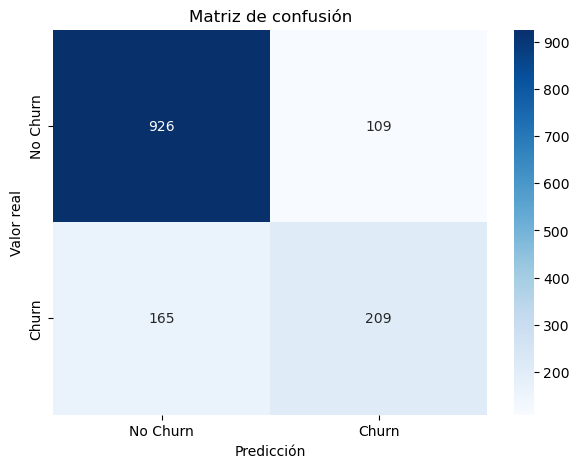

In [31]:
# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])

plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")

plt.show()

<Figure size 700x500 with 0 Axes>

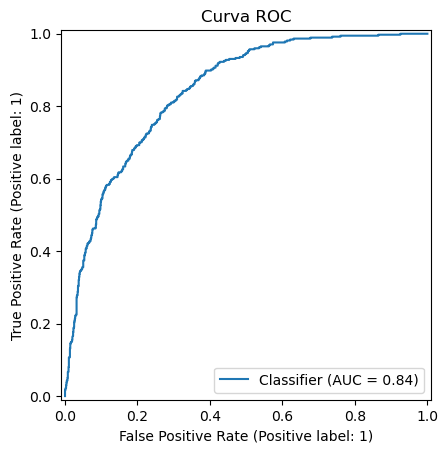

In [32]:
# Curva ROC
plt.figure(figsize=(7, 5))

RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("Curva ROC")
plt.show()

In [33]:
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  0.8055
Precision: 0.6572
Recall:    0.5588
F1-score:  0.6040
ROC-AUC:   0.8421


El modelo obtuvo un accuracy de 80.55%, sin embargo, con esta métrica no podemos ver el comportamiento del modelo. La precisión fue de 65.72%, indicando que, entre los clientes que el modelo identificó como posibles casos de Churn. El recall fue de 55.88%, por lo que el modelo logró identificar poco más de la mitad de los casos reales de abandono. El F1-score fue de 60.40%, proporcionando un balance entre precisión y recall. Por otro lado, el ROC-AUC fue de 84.20%, lo que indica una buena capacidad del modelo para distinguir entre ambas clases.
En el caso de la matriz de confusión podemos ver los verdaderos positivos, verdaderos negativos falsos positivos y los falsos negativos que tuvo nuestro modelo.
La curva ROC muestra cómo distinguir los clientes. El ROC de 0.842 muestra que si se puede discriminar pero no funciona sola, se debe tomar los otros parámetros evaluados.

-----
**Registra el experimento en MLFlow**

In [34]:

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Telco_Customer_Churn_Baseline")

<Experiment: artifact_location='file:C:/Users/gemma/Untitled Folder/mlruns/1', creation_time=1791011561530, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791011561530, lifecycle_stage='active', name='Telco_Customer_Churn_Baseline', tags={}, trace_location=None, workspace='default'>

In [35]:
with mlflow.start_run(run_name="Telco_Customer_Churn"):

    # Parametros
    mlflow.log_param("model", "LogisticRegression")
    
    mlflow.log_param("test_size", 0.20)
    
    mlflow.log_param("random_state", 42)
    
    mlflow.log_param("max_iter", 1000)
    
    mlflow.log_param("preprocessing", "StandardScaler + OneHotEncoder")
    
    # Métricas
    mlflow.log_metric("accuracy", accuracy)
    
    mlflow.log_metric("precision", precision)
    
    mlflow.log_metric("recall", recall)
    
    mlflow.log_metric("f1_score", f1)
    
    mlflow.log_metric("roc_auc", roc_auc)
    
    # Registrar el modelo
    mlflow.sklearn.log_model(pipeline, name="model")
    
    print("Experimento MLflow OK")

Experimento MLflow OK


In [36]:
experimentos = mlflow.search_runs(order_by=["start_time DESC"])

display(
    experimentos[["run_id", "status", "params.model", "params.test_size", "metrics.accuracy", "metrics.precision", "metrics.recall", 
                  "metrics.f1_score", "metrics.roc_auc"]])

,run_id,status,params.model,params.test_size,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.roc_auc
0,23030bb041004d2d85515f049187ca31,FINISHED,LogisticRegression,0.2,0.805536,0.657233,0.558824,0.604046,0.842135
1,3520886d56214814804e0f1324410755,FINISHED,LogisticRegression,0.2,0.805536,0.657233,0.558824,0.604046,0.842135
2,6c228eb676b34f4d92f8af5d056a94f6,FINISHED,LogisticRegression,0.2,0.805536,0.657233,0.558824,0.604046,0.842135
3,72d00a5e47f84500ae408d783d71014f,FINISHED,LogisticRegression,0.2,0.805536,0.657233,0.558824,0.604046,0.842034
4,624329ae3cf44056a2c83c0f60f72b27,FINISHED,LogisticRegression,0.2,0.805536,0.657233,0.558824,0.604046,0.842034


------
Fotos
https://drive.google.com/drive/folders/1bym6E3TzXEWg6TLx1vnjYxMztD8aTcEj?usp=sharing


![Imagenes MLFLOW](./MLFLOW2.png)
![Imagenes MLFLOW](./MLFLOW1.png)
![Imagenes MLFLOW](./MLFLOW.png)

-----
**Reflexión**

Durante esta actividad y conforme los errores que iba teniendo, me di cuenta que la parte del proceso y de mantener un orden es sumamente importante. Una de las principales mejoras que implementaría en un proyecto real sería automatizar las etapas de limpieza, verificación de datos (duplicados, faltantes, tipo de dato, formato incorrecto) para ir mitigando posibles inconsistencias antes de entrenar el modelo. Algo que a mi en lo personal me funcionó es en cada parte ir haciendo una copia por si en algo voy fallando poder restaurar.
Nunca había utilizado MLflow y me di cuenta de lo sencillo que es observar el seguimiento de experimentos facilita comparar modelos y sobre todo guardar la información de los parámetros, métricas y artefactos generados.De esta forma es más sencillo poder consultar y ver cual experimento tuvo un mejor desempeño.
Estos aprendizajes se relacionan con mi área profesional, ya que en mi anterior trabajo lo que se buscaba era conservar los datos y ver el mejor desempeño, por ahora me interesa trabajar en análisis de datos y aprender más técnicas para automatización y aplicaciones de inteligencia artificial. Lo de hoy son MLOps puede ayudarme a desarrollar soluciones más organizadas, mantenibles y fáciles de llevar de un análisis, que en las entrevistas de trabajo que he tenido me han preguntado sobre ello, por lo que considero que es sumamente importante el saber como funciona.

Referencias    
Command-Line Interface. (s. f.). https://mlflow.org/docs/latest/api_reference/cli.html - para dudas de comandos     
Google Gemini. (s. f.). Gemini. https://gemini.google.com - para una preevaluación y comprobación que se encuentre todo los de la rubrica, dudas sobre errores del code    
seaborn.boxplot — seaborn 0.13.2 documentation. (s. f.). https://seaborn.pydata.org/generated/seaborn.boxplot.html - para recordar las forma de grficar con sns    
Telco Customer Churn (s. f.-b)IBM. https://www.kaggle.com/datasets/blastchar/telco-customer-churn - base de datos   